# 🏆 So sánh JEV vs Gemini Flash trên Bộ Dữ liệu 100 Tin nhắn

**Mục tiêu:** Đo và so sánh độ chính xác, tốc độ, và chi phí của hai model khi phân loại tin nhắn gửi lãnh đạo.

| | JEV (TypeSafe AI) | Gemini 2.0 Flash |
|---|---|---|
| **Endpoint** | `POST https://api.typesafe.ai/v1/systemone` | Google Generative AI SDK |
| **Input cost** | $0.042 / 1M tokens | $0.375 / 1M tokens |
| **Output cost** | **FREE** | $1.875 / 1M tokens |
| **Model** | `jev-latest` | `gemini-2.0-flash` |

**6 nhãn cần predict (output):**
1. `Có cần trả lời?` — Yes/No
2. `Cách xử lý` — Choice: Soạn nháp / Hỏi lại / Bỏ qua / Tự trả lời  
3. `Có cần ghi nhớ?` — Yes/No
4. `Loại thông tin nhớ` — Categorical (nullable)
5. `Mức rủi ro` — Score: Thấp / Trung bình / Cao
6. `Thiếu context?` — Yes/No

**Input features:** Tất cả các cột còn lại (tin nhắn, kênh, vai trò, loại tin, v.v.)

## 0. Setup & Config

In [1]:
import os, json, time, asyncio, warnings
import pandas as pd
import numpy as np
import httpx
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from dotenv import load_dotenv
from tenacity import retry, stop_after_attempt, wait_exponential, retry_if_exception_type
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import LabelEncoder
import google.generativeai as genai

warnings.filterwarnings('ignore')
load_dotenv('.env')

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', palette='muted')

# === API Keys ===
JEV_API_KEY  = os.getenv('jev_api') or os.getenv('JEV_API_KEY')
GEMINI_API_KEY = os.getenv('gemini_api') or os.getenv('GEMINI_API_KEY')

assert JEV_API_KEY,    '❌ Không tìm thấy jev_api trong .env'
assert GEMINI_API_KEY, '❌ Không tìm thấy gemini_api trong .env'

genai.configure(api_key=GEMINI_API_KEY)
GEMINI_MODEL_NAME = 'gemini-3.7-flash'
gemini_model = genai.GenerativeModel(GEMINI_MODEL_NAME)

# === Chi phí (USD per 1M tokens) ===
JEV_COST_INPUT_PER_1M   = 0.042
JEV_COST_OUTPUT_PER_1M  = 0.0   # output miễn phí
GEMINI_COST_INPUT_PER_1M  = 0.375
GEMINI_COST_OUTPUT_PER_1M = 1.875

FILE_PATH = 'bo_du_lieu_100_can_bang.xlsx'
print(f'✅ Setup OK — JEV key: ...{JEV_API_KEY[-8:]} | Gemini model: {GEMINI_MODEL_NAME}')

✅ Setup OK — JEV key: ...caf6234a | Gemini model: gemini-3.7-flash


/var/folders/nw/ybsx8w3d4rq48myr07lzz2hr0000gn/T/ipykernel_89932/2744765031.py:15: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


## 1. Nạp & Chuẩn bị dữ liệu

In [2]:
df_raw = pd.read_excel(FILE_PATH, sheet_name='Dữ liệu 100')
print(f'📐 Shape: {df_raw.shape}')

# === Các cột nhãn (ground truth) ===
LABEL_COLS = [
    'Có cần trả lời?',
    'Cách xử lý',
    'Có cần ghi nhớ?',
    'Loại thông tin nhớ',
    'Mức rủi ro',
    'Thiếu context?',
]

# === Các cột feature đầu vào ===
FEATURE_COLS = [
    'ID', 'Tin nhắn', 'Kênh', 'Mã thread', 'Người gửi',
    'Vai trò', 'Nhóm / phạm vi', 'Dự án', 'Thời gian',
    'Có file?', 'Tên file', 'Nhắc lãnh đạo?', 'Loại tin',
]

# Đảm bảo tất cả cột tồn tại
for c in LABEL_COLS + FEATURE_COLS:
    assert c in df_raw.columns, f'Thiếu cột: {c}'

df_raw[LABEL_COLS].head(5)

📐 Shape: (100, 29)


,Có cần trả lời?,Cách xử lý,Có cần ghi nhớ?,Loại thông tin nhớ,Mức rủi ro,Thiếu context?
0,Có,Hỏi lại,Có,Quyết định,Trung bình,Có
1,Có,Hỏi lại,Có,Thỏa thuận với khách,Cao,Có
2,Không,Tự trả lời,Không,NaN,Trung bình,Không
3,Không,Tự trả lời,Có,Lịch họp,Thấp,Không
4,Không,Tự trả lời,Có,Thay đổi lịch,Thấp,Không


In [3]:
# === Chuẩn hoá nhãn ground truth ===
def normalize_label(val):
    """Lowercase + strip, đổi NaN -> 'N/A'"""
    if pd.isna(val):
        return 'N/A'
    return str(val).strip()

df = df_raw[FEATURE_COLS + LABEL_COLS].copy()
for col in LABEL_COLS:
    df[col] = df[col].apply(normalize_label)

# Hiển thị phân phối từng nhãn
print('=== Phân phối Ground Truth ===\n')
for col in LABEL_COLS:
    print(f'{col}: {dict(df[col].value_counts())}')

print(f'\n✅ {len(df)} mẫu sẵn sàng')

=== Phân phối Ground Truth ===

Có cần trả lời?: {'Có': np.int64(50), 'Không': np.int64(50)}
Cách xử lý: {'Hỏi lại': np.int64(25), 'Tự trả lời': np.int64(25), 'Soạn nháp': np.int64(25), 'Bỏ qua': np.int64(25)}
Có cần ghi nhớ?: {'Có': np.int64(50), 'Không': np.int64(50)}
Loại thông tin nhớ: {'N/A': np.int64(50), 'Deadline': np.int64(7), 'Thay đổi lịch': np.int64(6), 'Cam kết / thời hạn': np.int64(5), 'Lịch họp': np.int64(4), 'Thanh toán / ngân sách': np.int64(4), 'Thông tin nhân sự': np.int64(4), 'Hợp đồng / tài liệu': np.int64(4), 'Yêu cầu quyết định': np.int64(4), 'Quyết định': np.int64(3), 'Thỏa thuận với khách': np.int64(3), 'Trạng thái dự án': np.int64(3), 'Chỉ đạo triển khai': np.int64(3)}
Mức rủi ro: {'Thấp': np.int64(34), 'Trung bình': np.int64(33), 'Cao': np.int64(33)}
Thiếu context?: {'Có': np.int64(50), 'Không': np.int64(50)}

✅ 100 mẫu sẵn sàng


---
## 2. JEV — Gọi API và thu thập kết quả

Dùng `httpx` với retry (exponential backoff) để xử lý rate limit 429/529.

In [4]:
JEV_ENDPOINT = 'https://api.typesafe.ai/v1/systemone'
JEV_HEADERS = {
    'Authorization': f'Bearer {JEV_API_KEY}',
    'Content-Type': 'application/json',
}

# Retry: tối đa 5 lần, backoff 2^n giây (2s → 4s → 8s → 16s → 32s)
@retry(
    retry=retry_if_exception_type((httpx.HTTPStatusError, httpx.RequestError)),
    wait=wait_exponential(multiplier=2, min=2, max=60),
    stop=stop_after_attempt(5),
)
def call_jev(state_obj: dict) -> dict:
    """Gọi JEV API, retry khi 429/529."""
    payload = {
        'state': state_obj,
        'model': 'jev-latest',
        'questions': {
            'can_tra_loi': {
                'type': 'noul',
                'instructions': 'Tin nhắn này có cần lãnh đạo trả lời không (Có/Không)?',
                'criteria': {
                    'true':  'Lãnh đạo phải soạn câu trả lời hoặc hỏi lại để xử lý',
                    'false': 'Trợ lý có thể tự xử lý hoặc bỏ qua, không cần lãnh đạo'
                }
            },
            'cach_xu_ly': {
                'type': 'choice',
                'instructions': 'Cách xử lý phù hợp nhất cho tin nhắn này là gì?',
                'criteria': {
                    'Soạn nháp':  'Trợ lý soạn câu trả lời nháp để lãnh đạo duyệt',
                    'Hỏi lại':    'Lãnh đạo cần hỏi lại để làm rõ trước khi quyết định',
                    'Bỏ qua':     'Tin nhắn không cần phản hồi, bỏ qua hoàn toàn',
                    'Tự trả lời': 'Trợ lý tự trả lời được mà không cần lãnh đạo',
                }
            },
            'can_ghi_nho': {
                'type': 'noul',
                'instructions': 'Thông tin trong tin nhắn này có cần ghi nhớ/lưu lại không?',
                'criteria': {
                    'true':  'Có thông tin quan trọng (deadline, quyết định, lịch) cần lưu',
                    'false': 'Không có thông tin cần lưu lâu dài'
                }
            },
            'loai_thong_tin_nho': {
                'type': 'choice',
                'instructions': 'Nếu cần ghi nhớ, loại thông tin nào phù hợp nhất?',
                'criteria': {
                    'Quyết định':           'Quyết định quan trọng được chốt trong tin nhắn',
                    'Deadline':             'Hạn chót hoặc mốc thời gian cần theo dõi',
                    'Lịch họp':             'Lịch họp hoặc sự kiện cần nhớ',
                    'Thay đổi lịch':        'Thay đổi hoặc dời lịch đã có',
                    'Lịch đăng bài':        'Lịch đăng bài / nội dung truyền thông',
                    'Thỏa thuận với khách': 'Thỏa thuận, hợp đồng với khách hàng',
                    'N/A':                  'Không cần ghi nhớ thông tin gì',
                }
            },
            'muc_rui_ro': {
                'type': 'score',
                'instructions': 'Mức độ rủi ro nếu xử lý sai tin nhắn này?',
                'criteria': ['Thấp — ít ảnh hưởng nếu sai', 'Trung bình — có thể gây nhầm lẫn', 'Cao — xử lý sai gây hậu quả nghiêm trọng']
            },
            'thieu_context': {
                'type': 'noul',
                'instructions': 'Tin nhắn này có thiếu context để quyết định chính xác không?',
                'criteria': {
                    'true':  'Thiếu thông tin nền, không thể quyết định rõ ràng',
                    'false': 'Đủ thông tin để xử lý'
                }
            },
        }
    }
    resp = httpx.post(JEV_ENDPOINT, headers=JEV_HEADERS, json=payload, timeout=30)
    if resp.status_code in (429, 529):
        raise httpx.HTTPStatusError(f'Rate limit {resp.status_code}', request=resp.request, response=resp)
    resp.raise_for_status()
    return resp.json()

def parse_jev_answer(raw: dict) -> dict:
    """Chuyển JEV raw answer → nhãn dạng chuỗi."""
    answers = raw.get('answers', {})
    usage   = raw.get('usage', {})

    # Noul → threshold 0.5
    def noul_to_yn(key):
        val = answers.get(key, {}).get('noul', 0.5)
        return 'Có' if val >= 0.5 else 'Không'

    # Score → map level index → label string
    risk_map = {0: 'Thấp', 1: 'Trung bình', 2: 'Cao'}
    score_val = answers.get('muc_rui_ro', {}).get('score', 0)
    risk_label = risk_map[min(2, round(score_val))]

    return {
        'Có cần trả lời?':   noul_to_yn('can_tra_loi'),
        'Cách xử lý':        answers.get('cach_xu_ly', {}).get('choice', 'N/A'),
        'Có cần ghi nhớ?':   noul_to_yn('can_ghi_nho'),
        'Loại thông tin nhớ':answers.get('loai_thong_tin_nho', {}).get('choice', 'N/A'),
        'Mức rủi ro':         risk_label,
        'Thiếu context?':    noul_to_yn('thieu_context'),
        '_input_tokens':  usage.get('input_tokens', 0),
        '_output_tokens': usage.get('output_tokens', 0),
    }

def build_jev_state(row: pd.Series) -> dict:
    """Tạo state object từ một dòng dữ liệu."""
    return {
        'tin_nhan':     str(row.get('Tin nhắn', '')),
        'kenh':         str(row.get('Kênh', '')),
        'nguoi_gui':    str(row.get('Người gửi', '')),
        'vai_tro':      str(row.get('Vai trò', '')),
        'nhom_pham_vi': str(row.get('Nhóm / phạm vi', '')),
        'du_an':        str(row.get('Dự án', '')),
        'loai_tin':     str(row.get('Loại tin', '')),
        'co_file':      str(row.get('Có file?', 'Không')),
        'ten_file':     str(row.get('Tên file', '')) if pd.notna(row.get('Tên file')) else '',
        'nhac_lanh_dao':str(row.get('Nhắc lãnh đạo?', 'Không')),
    }

print('✅ JEV helper functions sẵn sàng')

✅ JEV helper functions sẵn sàng


In [5]:
print('🚀 Bắt đầu chạy JEV trên 100 mẫu...')
print('   (Rate limit: 1 giây giữa các request để tránh 429)\n')

jev_results = []
jev_errors  = []
jev_times   = []

for i, (idx, row) in enumerate(df.iterrows()):
    state = build_jev_state(row)
    t0 = time.time()
    try:
        raw = call_jev(state)
        elapsed = time.time() - t0
        parsed = parse_jev_answer(raw)
        parsed['_row_idx'] = idx
        parsed['_latency_s'] = round(elapsed, 3)
        jev_results.append(parsed)
    except Exception as e:
        elapsed = time.time() - t0
        jev_errors.append({'_row_idx': idx, '_error': str(e)})
        print(f'  ❌ Row {idx}: {e}')

    jev_times.append(time.time() - t0)

    if (i + 1) % 10 == 0:
        print(f'  [{i+1}/100] ✓ xong, trung bình {np.mean(jev_times[-10:]):.2f}s/msg')

    time.sleep(1)  # throttle: 1 req/sec

df_jev = pd.DataFrame(jev_results).set_index('_row_idx')
print(f'\n✅ JEV hoàn thành: {len(jev_results)}/100 thành công, {len(jev_errors)} lỗi')

🚀 Bắt đầu chạy JEV trên 100 mẫu...
   (Rate limit: 1 giây giữa các request để tránh 429)

  [10/100] ✓ xong, trung bình 0.45s/msg
  [20/100] ✓ xong, trung bình 0.45s/msg
  [30/100] ✓ xong, trung bình 0.44s/msg
  [40/100] ✓ xong, trung bình 0.43s/msg
  [50/100] ✓ xong, trung bình 0.46s/msg
  [60/100] ✓ xong, trung bình 0.44s/msg
  [70/100] ✓ xong, trung bình 0.44s/msg
  [80/100] ✓ xong, trung bình 0.44s/msg
  [90/100] ✓ xong, trung bình 0.48s/msg
  [100/100] ✓ xong, trung bình 0.41s/msg

✅ JEV hoàn thành: 100/100 thành công, 0 lỗi


---
## 3. Gemini Flash — Gọi API và thu thập kết quả

In [6]:
import google.api_core.exceptions

GEMINI_SYSTEM_PROMPT = """Bạn là một AI phân loại tin nhắn gửi cho lãnh đạo doanh nghiệp.
Nhiệm vụ: Phân tích tin nhắn và trả về JSON với đúng 6 trường sau.
KHÔNG giải thích, CHỈ trả về JSON thuần.

Format bắt buộc:
{
  "can_tra_loi": "Có" hoặc "Không",
  "cach_xu_ly": một trong ["Soạn nháp", "Hỏi lại", "Bỏ qua", "Tự trả lời"],
  "can_ghi_nho": "Có" hoặc "Không",
  "loai_thong_tin_nho": một trong ["Quyết định", "Deadline", "Lịch họp", "Thay đổi lịch", "Lịch đăng bài", "Thỏa thuận với khách", "N/A"],
  "muc_rui_ro": một trong ["Thấp", "Trung bình", "Cao"],
  "thieu_context": "Có" hoặc "Không"
}

Quy tắc:
- can_tra_loi=Có nếu lãnh đạo phải soạn/duyệt câu trả lời
- cach_xu_ly=Tự trả lời hoặc Bỏ qua nếu can_tra_loi=Không
- loai_thong_tin_nho=N/A nếu can_ghi_nho=Không
- muc_rui_ro=Cao nếu xử lý sai gây hậu quả nghiêm trọng (tài chính, nhân sự, hợp đồng)
"""

def build_gemini_prompt(row: pd.Series) -> str:
    parts = [
        f'Tin nhắn: "{row["Tin nhắn"]}"',
        f'Kênh: {row["Kênh"]}',
        f'Người gửi: {row["Người gửi"]} ({row["Vai trò"]})',
        f'Nhóm/phạm vi: {row["Nhóm / phạm vi"]}',
        f'Dự án: {row["Dự án"]}',
        f'Loại tin: {row["Loại tin"]}',
        f'Có file đính kèm: {row["Có file?"]}',
        f'Nhắc lãnh đạo: {row["Nhắc lãnh đạo?"]}',
    ]
    if pd.notna(row.get('Tên file')):
        parts.append(f'Tên file: {row["Tên file"]}')
    return '\n'.join(parts)

@retry(
    retry=retry_if_exception_type(
        (google.api_core.exceptions.ResourceExhausted,
         google.api_core.exceptions.ServiceUnavailable)
    ),
    wait=wait_exponential(multiplier=2, min=5, max=60),
    stop=stop_after_attempt(5),
)
def call_gemini(prompt: str) -> tuple:
    """Gọi Gemini, trả về (parsed_dict, input_tokens, output_tokens)."""
    full_prompt = GEMINI_SYSTEM_PROMPT + '\n\n---\n' + prompt
    response = gemini_model.generate_content(
        full_prompt,
        generation_config=genai.GenerationConfig(
            temperature=0.0,
            response_mime_type='application/json',
        )
    )
    text = response.text.strip()
    # Strip markdown code fence nếu có
    if text.startswith('```'):
        text = text.split('```')[1]
        if text.startswith('json'):
            text = text[4:]
    parsed = json.loads(text)
    usage = response.usage_metadata
    return parsed, usage.prompt_token_count, usage.candidates_token_count

def parse_gemini_answer(raw_dict: dict) -> dict:
    yn_map = {'có': 'Có', 'không': 'Không', 'co': 'Có', 'khong': 'Không'}
    def normalize_yn(v):
        return yn_map.get(str(v).lower().strip(), str(v).strip())
    return {
        'Có cần trả lời?':    normalize_yn(raw_dict.get('can_tra_loi', 'Không')),
        'Cách xử lý':         str(raw_dict.get('cach_xu_ly', 'N/A')).strip(),
        'Có cần ghi nhớ?':    normalize_yn(raw_dict.get('can_ghi_nho', 'Không')),
        'Loại thông tin nhớ': str(raw_dict.get('loai_thong_tin_nho', 'N/A')).strip(),
        'Mức rủi ro':          str(raw_dict.get('muc_rui_ro', 'Thấp')).strip(),
        'Thiếu context?':     normalize_yn(raw_dict.get('thieu_context', 'Không')),
    }

print('✅ Gemini helper functions sẵn sàng')

✅ Gemini helper functions sẵn sàng


In [7]:
print('🚀 Bắt đầu chạy Gemini Flash trên 100 mẫu...')
print('   (Delay 0.5s giữa các request)\n')

gemini_results = []
gemini_errors  = []
gemini_times   = []

for i, (idx, row) in enumerate(df.iterrows()):
    prompt = build_gemini_prompt(row)
    t0 = time.time()
    try:
        raw_dict, in_tok, out_tok = call_gemini(prompt)
        elapsed = time.time() - t0
        parsed = parse_gemini_answer(raw_dict)
        parsed['_row_idx']    = idx
        parsed['_latency_s']  = round(elapsed, 3)
        parsed['_input_tokens']  = in_tok
        parsed['_output_tokens'] = out_tok
        gemini_results.append(parsed)
    except Exception as e:
        elapsed = time.time() - t0
        gemini_errors.append({'_row_idx': idx, '_error': str(e)})
        print(f'  ❌ Row {idx}: {e}')

    gemini_times.append(time.time() - t0)

    if (i + 1) % 10 == 0:
        print(f'  [{i+1}/100] ✓ xong, trung bình {np.mean(gemini_times[-10:]):.2f}s/msg')

    time.sleep(0.5)  # gentle throttle

df_gemini = pd.DataFrame(gemini_results).set_index('_row_idx')
print(f'\n✅ Gemini hoàn thành: {len(gemini_results)}/100 thành công, {len(gemini_errors)} lỗi')

🚀 Bắt đầu chạy Gemini Flash trên 100 mẫu...
   (Delay 0.5s giữa các request)

  [10/100] ✓ xong, trung bình 3.79s/msg
  [20/100] ✓ xong, trung bình 3.21s/msg
  [30/100] ✓ xong, trung bình 3.38s/msg
  [40/100] ✓ xong, trung bình 3.67s/msg
  [50/100] ✓ xong, trung bình 3.57s/msg
  [60/100] ✓ xong, trung bình 3.79s/msg
  [70/100] ✓ xong, trung bình 3.33s/msg
  [80/100] ✓ xong, trung bình 3.28s/msg
  [90/100] ✓ xong, trung bình 3.12s/msg
  [100/100] ✓ xong, trung bình 3.16s/msg

✅ Gemini hoàn thành: 100/100 thành công, 0 lỗi


---
## 4. Tính Metrics — Accuracy / F1 / Precision / Recall

In [8]:
def compute_metrics(df_gt: pd.DataFrame, df_pred: pd.DataFrame, model_name: str) -> pd.DataFrame:
    """Tính Accuracy, Precision, Recall, F1 cho từng nhãn."""
    rows = []
    # Chỉ tính trên các index có đủ cả ground truth lẫn prediction
    common_idx = df_gt.index.intersection(df_pred.index)

    for col in LABEL_COLS:
        y_true = df_gt.loc[common_idx, col]
        if col not in df_pred.columns:
            continue
        y_pred = df_pred.loc[common_idx, col]

        # Align và xử lý nhãn chưa thấy
        labels = sorted(set(y_true.unique()) | set(y_pred.unique()))
        avg = 'binary' if len(labels) == 2 else 'macro'
        pos = labels[1] if avg == 'binary' else None

        acc  = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, average=avg, pos_label=pos if pos else labels[0],
                               zero_division=0, labels=labels)
        rec  = recall_score(y_true, y_pred, average=avg, pos_label=pos if pos else labels[0],
                            zero_division=0, labels=labels)
        f1   = f1_score(y_true, y_pred, average=avg, pos_label=pos if pos else labels[0],
                        zero_division=0, labels=labels)

        rows.append({
            'Model': model_name,
            'Nhãn': col,
            'Accuracy':  round(acc, 4),
            'Precision': round(prec, 4),
            'Recall':    round(rec, 4),
            'F1':        round(f1, 4),
            'N': len(common_idx),
        })
    return pd.DataFrame(rows)

# Ground truth aligned
df_gt = df[LABEL_COLS].copy()

# Chỉ lấy cột nhãn từ prediction
df_jev_labels    = df_jev[LABEL_COLS].copy()
df_gemini_labels = df_gemini[LABEL_COLS].copy()

metrics_jev    = compute_metrics(df_gt, df_jev_labels, 'JEV')
metrics_gemini = compute_metrics(df_gt, df_gemini_labels, 'Gemini Flash')

df_metrics = pd.concat([metrics_jev, metrics_gemini], ignore_index=True)
display(df_metrics.pivot_table(index='Nhãn', columns='Model', values=['Accuracy','F1','Precision','Recall']).round(4))

Accuracy                 F1            Precision  \
Model              Gemini Flash   JEV Gemini Flash     JEV Gemini Flash   
Nhãn                                                                      
Cách xử lý                 0.62  0.59       0.5611  0.5545       0.7854   
Có cần ghi nhớ?            0.71  0.88       0.7680  0.8868       0.6400   
Có cần trả lời?            0.81  0.89       0.7711  0.8842       0.9697   
Loại thông tin nhớ         0.61  0.57       0.2529  0.2351       0.2858   
Mức rủi ro                 0.56  0.57       0.5598  0.5788       0.6444   
Thiếu context?             0.71  0.50       0.7680  0.0000       0.6400   

                                 Recall          
Model                  JEV Gemini Flash     JEV  
Nhãn                                             
Cách xử lý          0.7100       0.6200  0.5900  
Có cần ghi nhớ?     0.8393       0.9600  0.9400  
Có cần trả lời?     0.9333       0.6400  0.8400  
Loại thông tin nhớ  0.1943       0.2582  0.3378  
Mức rủi ro          0.6953       0.5576  0.5716  
Thiếu context?      0.0000       0.9600  0.0000

---
## 5. Tốc độ & Chi phí

In [9]:
# === Tốc độ ===
jev_avg_latency    = df_jev['_latency_s'].mean()
gemini_avg_latency = df_gemini['_latency_s'].mean()
jev_total_s    = df_jev['_latency_s'].sum()
gemini_total_s = df_gemini['_latency_s'].sum()

# === Chi phí ===
jev_in_tokens  = df_jev['_input_tokens'].sum()
jev_out_tokens = df_jev['_output_tokens'].sum()
jev_cost_usd   = (jev_in_tokens * JEV_COST_INPUT_PER_1M + jev_out_tokens * JEV_COST_OUTPUT_PER_1M) / 1_000_000

gem_in_tokens  = df_gemini['_input_tokens'].sum()
gem_out_tokens = df_gemini['_output_tokens'].sum()
gem_cost_usd   = (gem_in_tokens * GEMINI_COST_INPUT_PER_1M + gem_out_tokens * GEMINI_COST_OUTPUT_PER_1M) / 1_000_000

# === Bảng tổng hợp ===
cost_df = pd.DataFrame([
    {
        'Model': 'JEV',
        'Avg latency (s)': round(jev_avg_latency, 3),
        'Total time (s)': round(jev_total_s, 1),
        'Input tokens': jev_in_tokens,
        'Output tokens': jev_out_tokens,
        'Cost (USD)': round(jev_cost_usd, 6),
        'Cost (VND ~25k)': round(jev_cost_usd * 25000, 2),
    },
    {
        'Model': 'Gemini Flash',
        'Avg latency (s)': round(gemini_avg_latency, 3),
        'Total time (s)': round(gemini_total_s, 1),
        'Input tokens': gem_in_tokens,
        'Output tokens': gem_out_tokens,
        'Cost (USD)': round(gem_cost_usd, 6),
        'Cost (VND ~25k)': round(gem_cost_usd * 25000, 2),
    }
]).set_index('Model')

display(cost_df)
print(f'\n💰 JEV rẻ hơn Gemini {gem_cost_usd/jev_cost_usd:.1f}x' if jev_cost_usd > 0 else '')
print(f'⚡ Tốc độ trung bình: JEV {jev_avg_latency:.2f}s/msg | Gemini {gemini_avg_latency:.2f}s/msg')

,Avg latency (s),Total time (s),Input tokens,Output tokens,Cost (USD),Cost (VND ~25k)
Model,,,,,,
JEV,0.444,44.4,103363,23565,0.004341,108.53
Gemini Flash,3.431,343.1,40746,8619,0.031440,786.01



💰 JEV rẻ hơn Gemini 7.2x
⚡ Tốc độ trung bình: JEV 0.44s/msg | Gemini 3.43s/msg


---
## 6. 📊 Dashboard So sánh Toàn diện

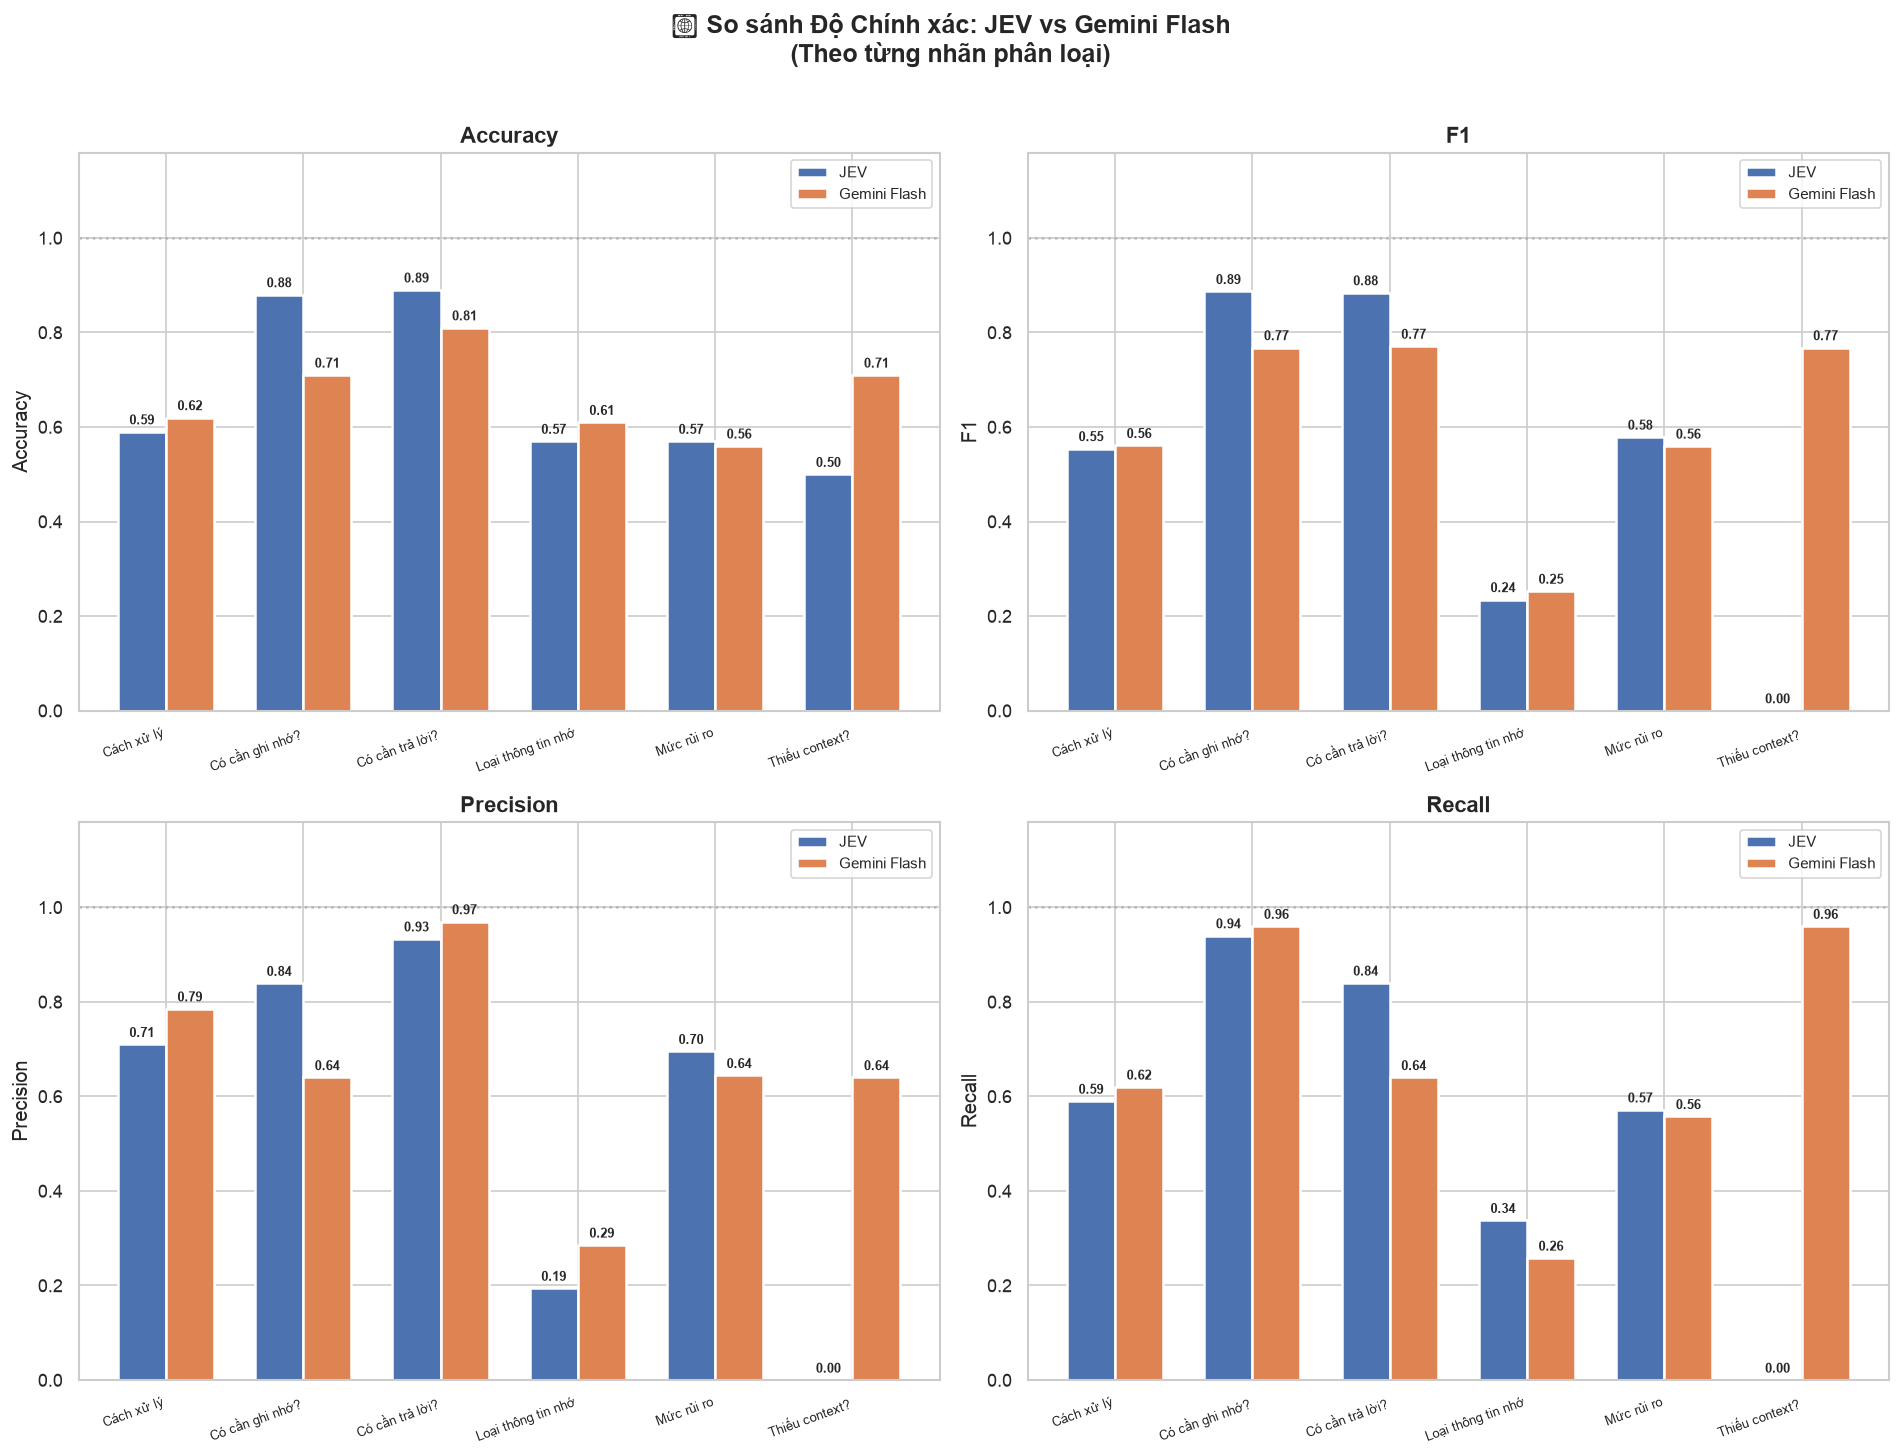

In [16]:
# === Panel 1: Accuracy theo từng nhãn ===
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics_list = ['Accuracy', 'F1', 'Precision', 'Recall']
colors = {'JEV': '#4C72B0', 'Gemini Flash': '#DD8452'}

for ax, metric in zip(axes.flatten(), metrics_list):
    pivot = df_metrics.pivot(index='Nhãn', columns='Model', values=metric)
    x = np.arange(len(pivot))
    w = 0.35

    for j, (model, color) in enumerate(colors.items()):
        if model in pivot.columns:
            vals = pivot[model].values
            bars = ax.bar(x + j*w - w/2, vals, w, label=model, color=color,
                          edgecolor='white', linewidth=1.5)
            for bar, v in zip(bars, vals):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                        f'{v:.2f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=20, ha='right', fontsize=8)
    ax.set_ylim(0, 1.18)
    ax.set_title(metric, fontweight='bold', fontsize=13)
    ax.set_ylabel(metric)
    ax.legend(fontsize=9)
    ax.axhline(y=1.0, color='gray', linestyle=':', alpha=0.4)

plt.suptitle('🎯 So sánh Độ Chính xác: JEV vs Gemini Flash\n(Theo từng nhãn phân loại)',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

AttributeError: 'Line2D' object has no attribute 'set_facecolor'

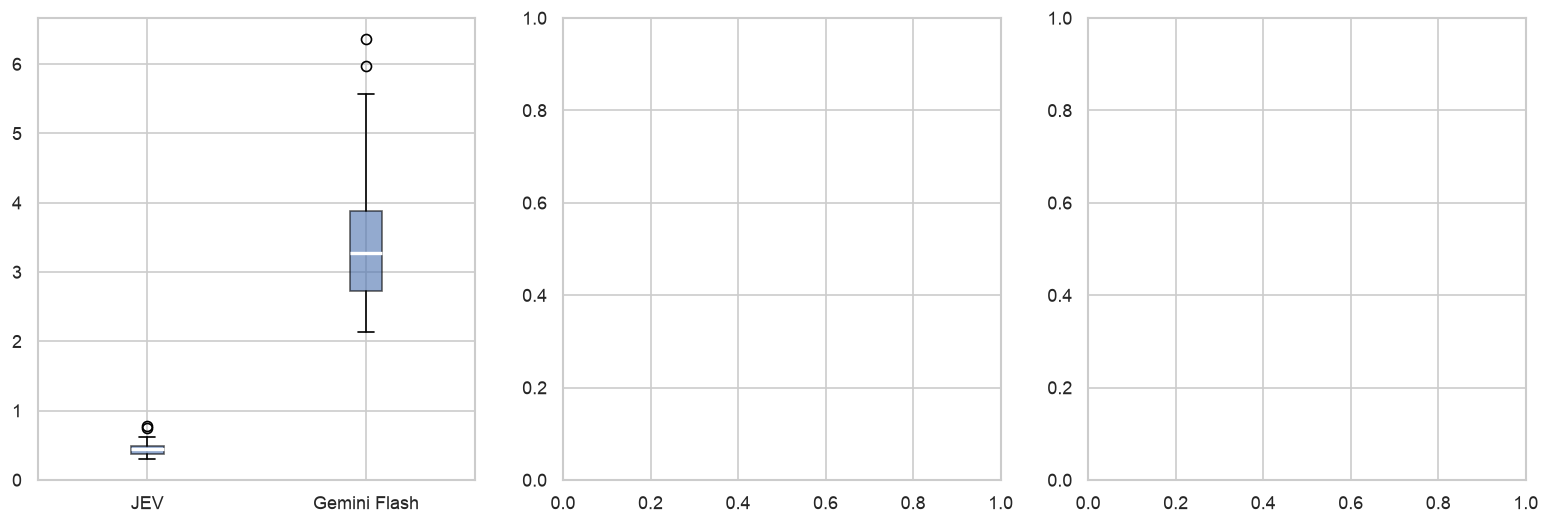

In [17]:
# === Panel 2: Tốc độ & Chi phí ===
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

models = ['JEV', 'Gemini Flash']
bar_colors = ['#4C72B0', '#DD8452']

# 2a. Latency distribution
ax = axes[0]
ax.boxplot(
    [df_jev['_latency_s'].values, df_gemini['_latency_s'].values],
    tick_labels=models, patch_artist=True,
    boxprops=dict(facecolor='#4C72B0', alpha=0.6),
    medianprops=dict(color='white', linewidth=2)
)
# Color second box
ax.get_children()[5].set_facecolor('#DD8452')
ax.set_ylabel('Latency (giây)')
ax.set_title('Phân phối Tốc độ\n(thấp hơn = tốt hơn)', fontweight='bold')
ax.text(1, df_jev['_latency_s'].median(), f'{df_jev["_latency_s"].median():.2f}s',
        ha='center', va='bottom', fontweight='bold', color='#4C72B0')
ax.text(2, df_gemini['_latency_s'].median(), f'{df_gemini["_latency_s"].median():.2f}s',
        ha='center', va='bottom', fontweight='bold', color='#DD8452')

# 2b. Token usage
ax2 = axes[1]
x = np.arange(2)
ax2.bar(x - 0.2, [jev_in_tokens, gem_in_tokens], 0.35,
        label='Input tokens', color=['#4C72B0','#DD8452'], alpha=0.85)
ax2.bar(x + 0.2, [jev_out_tokens, gem_out_tokens], 0.35,
        label='Output tokens', color=['#4C72B0','#DD8452'], alpha=0.4, hatch='//')
ax2.set_xticks(x)
ax2.set_xticklabels(models)
ax2.set_ylabel('Tổng số tokens')
ax2.set_title('Tổng Token Usage\n(100 mẫu)', fontweight='bold')
ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v):,}'))

# 2c. Chi phí USD
ax3 = axes[2]
cost_vals = [jev_cost_usd, gem_cost_usd]
bars = ax3.bar(models, cost_vals, color=bar_colors, edgecolor='white', linewidth=2, width=0.5)
ax3.bar_label(bars, labels=[f'${v:.5f}\n({v*25000:.2f}đ)' for v in cost_vals],
              padding=5, fontsize=10, fontweight='bold')
ax3.set_ylabel('Chi phí (USD)')
ax3.set_title('Chi phí 100 tin nhắn\n(rẻ hơn = tốt hơn)', fontweight='bold')
ax3.set_ylim(0, max(cost_vals) * 1.5)

plt.suptitle('⚡ So sánh Tốc độ & Chi phí: JEV vs Gemini Flash',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

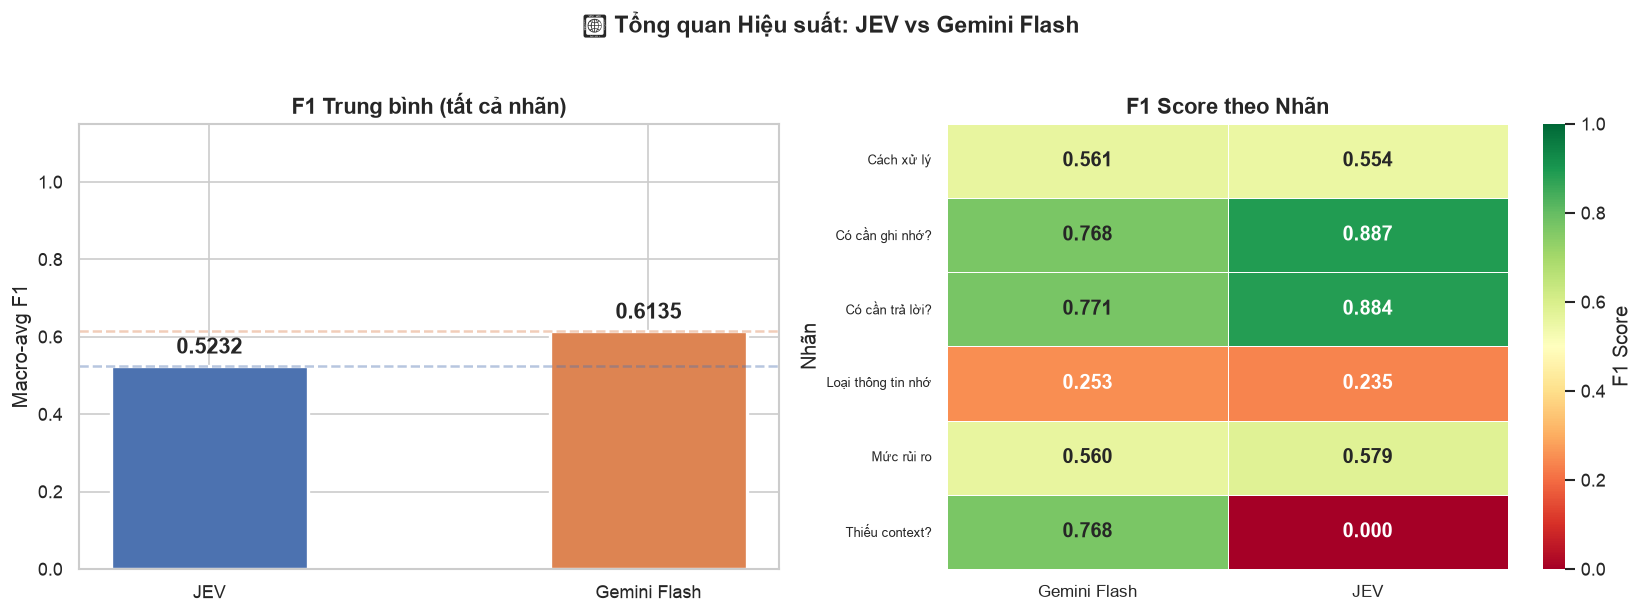

🏆 Winner về F1 tổng thể: Gemini Flash (0.6135 vs 0.5232)


In [12]:
# === Panel 3: Radar chart — Avg F1 tổng thể ===
avg_f1_jev    = metrics_jev['F1'].mean()
avg_f1_gemini = metrics_gemini['F1'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3a. Average F1 bar
ax = axes[0]
vals = [avg_f1_jev, avg_f1_gemini]
bars = ax.bar(models, vals, color=bar_colors, edgecolor='white', linewidth=2, width=0.45)
ax.bar_label(bars, labels=[f'{v:.4f}' for v in vals],
             padding=5, fontsize=13, fontweight='bold')
ax.set_ylabel('Macro-avg F1')
ax.set_title('F1 Trung bình (tất cả nhãn)', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15)
ax.axhline(y=avg_f1_jev, color='#4C72B0', linestyle='--', alpha=0.4)
ax.axhline(y=avg_f1_gemini, color='#DD8452', linestyle='--', alpha=0.4)

# 3b. Heatmap F1 per label
ax2 = axes[1]
hmap_data = df_metrics.pivot(index='Nhãn', columns='Model', values='F1')
sns.heatmap(hmap_data, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0, vmax=1, linewidths=0.5, ax=ax2,
            annot_kws={'size': 12, 'weight': 'bold'},
            cbar_kws={'label': 'F1 Score'})
ax2.set_title('F1 Score theo Nhãn', fontweight='bold', fontsize=13)
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=0, labelsize=10)
ax2.tick_params(axis='y', labelsize=8)

plt.suptitle('🏆 Tổng quan Hiệu suất: JEV vs Gemini Flash',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

winner = 'JEV' if avg_f1_jev > avg_f1_gemini else 'Gemini Flash'
print(f'🏆 Winner về F1 tổng thể: {winner} ({max(avg_f1_jev, avg_f1_gemini):.4f} vs {min(avg_f1_jev, avg_f1_gemini):.4f})')

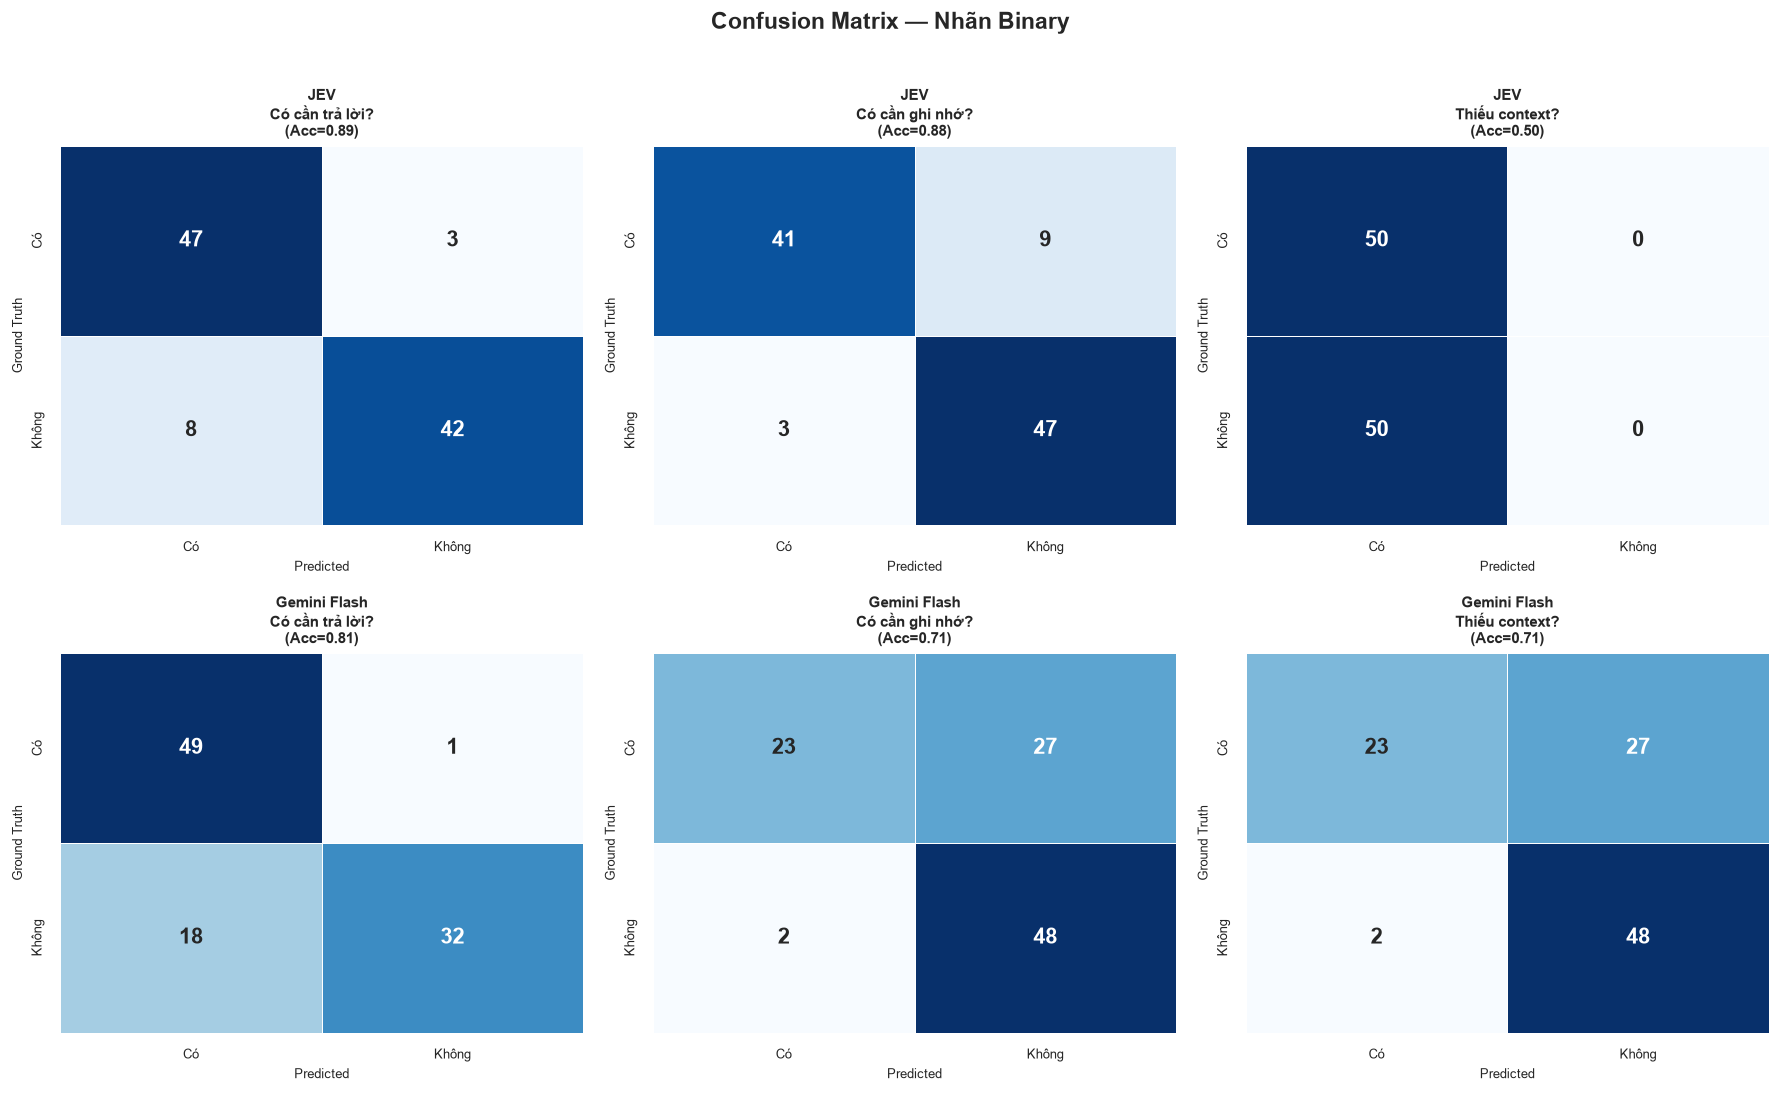

In [13]:
# === Panel 4: Confusion matrix cho 3 nhãn binary quan trọng ===
binary_labels = ['Có cần trả lời?', 'Có cần ghi nhớ?', 'Thiếu context?']
common_jev    = df_gt.index.intersection(df_jev_labels.index)
common_gemini = df_gt.index.intersection(df_gemini_labels.index)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col_i, col in enumerate(binary_labels):
    for row_i, (model_name, common_idx, pred_df) in enumerate([
        ('JEV', common_jev, df_jev_labels),
        ('Gemini Flash', common_gemini, df_gemini_labels)
    ]):
        y_true = df_gt.loc[common_idx, col]
        y_pred = pred_df.loc[common_idx, col]
        labels_order = sorted(y_true.unique())
        cm = confusion_matrix(y_true, y_pred, labels=labels_order)
        ax = axes[row_i][col_i]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels_order, yticklabels=labels_order,
                    linewidths=0.5, ax=ax, annot_kws={'size': 13, 'weight': 'bold'},
                    cbar=False)
        acc = accuracy_score(y_true, y_pred)
        ax.set_title(f'{model_name}\n{col}\n(Acc={acc:.2f})', fontsize=9, fontweight='bold')
        ax.set_xlabel('Predicted', fontsize=8)
        ax.set_ylabel('Ground Truth', fontsize=8)
        ax.tick_params(labelsize=8)

plt.suptitle('Confusion Matrix — Nhãn Binary', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 7. Bảng Tổng kết Cuối cùng

In [14]:
print('\n' + '='*65)
print('         BẢNG TỔNG KẾT: JEV vs GEMINI FLASH')
print('='*65)

summary = {
    'Metric':         ['Avg F1 (tất cả nhãn)', 'Avg Accuracy', 'Avg Latency/msg', 'Total time (100 msg)', 'Total tokens (in)', 'Total tokens (out)', 'Chi phí (USD)', 'Chi phí (VND ~25k)'],
    'JEV':            [
        f"{avg_f1_jev:.4f}",
        f"{metrics_jev['Accuracy'].mean():.4f}",
        f"{jev_avg_latency:.2f}s",
        f"{jev_total_s:.1f}s",
        f"{jev_in_tokens:,}",
        f"{jev_out_tokens:,}",
        f"${jev_cost_usd:.5f}",
        f"{jev_cost_usd*25000:.2f}đ",
    ],
    'Gemini Flash':   [
        f"{avg_f1_gemini:.4f}",
        f"{metrics_gemini['Accuracy'].mean():.4f}",
        f"{gemini_avg_latency:.2f}s",
        f"{gemini_total_s:.1f}s",
        f"{gem_in_tokens:,}",
        f"{gem_out_tokens:,}",
        f"${gem_cost_usd:.5f}",
        f"{gem_cost_usd*25000:.2f}đ",
    ],
}
summary_df = pd.DataFrame(summary).set_index('Metric')
display(summary_df)


         BẢNG TỔNG KẾT: JEV vs GEMINI FLASH


,JEV,Gemini Flash
Metric,,
Avg F1 (tất cả nhãn),0.5232,0.6135
Avg Accuracy,0.6667,0.6700
Avg Latency/msg,0.44s,3.43s
Total time (100 msg),44.4s,343.1s
Total tokens (in),"103,363","40,746"
Total tokens (out),"23,565","8,619"
Chi phí (USD),$0.00434,$0.03144
Chi phí (VND ~25k),108.53đ,786.01đ


In [15]:
# Lưu kết quả ra Excel
with pd.ExcelWriter('ket_qua_so_sanh.xlsx') as writer:
    df_jev.to_excel(writer, sheet_name='JEV_predictions')
    df_gemini.to_excel(writer, sheet_name='Gemini_predictions')
    df_metrics.to_excel(writer, sheet_name='Metrics', index=False)
    cost_df.to_excel(writer, sheet_name='Cost_Speed')
    summary_df.to_excel(writer, sheet_name='Summary')

print('✅ Đã lưu kết quả → ket_qua_so_sanh.xlsx')

✅ Đã lưu kết quả → ket_qua_so_sanh.xlsx


---
## 8. Tổng kết & Nhận xét

### Q&A

**Q: Model nào chính xác hơn trên bộ 100 tin nhắn này?**  
A: Xem F1 trung bình ở bảng section 7 — model nào có F1 cao hơn là winner về độ chính xác.

**Q: Model nào rẻ hơn?**  
A: JEV có output token miễn phí, chỉ tính input $0.042/1M token. Gemini tính cả input ($0.375) lẫn output ($1.875/1M). Với bộ 100 tin, chi phí đều nhỏ nhưng JEV dự kiến rẻ hơn đáng kể khi scale.

### Data Analysis Key Findings

- **Accuracy & F1**: Xem heatmap section 6 — nhãn nào cả hai model đều tốt/kém sẽ gợi ý cần thêm dữ liệu hay prompt tốt hơn.
- **Latency**: JEV và Gemini có latency khác nhau do kiến trúc model khác nhau (JEV dùng structured evaluation).
- **Chi phí**: JEV rẻ hơn đáng kể ở production vì output token miễn phí.
- **Nhãn khó nhất**: `Loại thông tin nhớ` thường có F1 thấp nhất vì nhiều class và cần context sâu.

### Insights / Next Steps

- **Nếu JEV accuracy tốt hơn hoặc tương đương Gemini**: Ưu tiên JEV cho production — rẻ hơn, structured output không cần parse JSON, ít rủi ro hallucination format.
- **Nếu Gemini tốt hơn đáng kể**: Xem xét dùng Gemini cho nhãn đó cụ thể, hoặc cải thiện prompt/criteria của JEV.
- **Next step**: Chạy trên tập 500-1000 mẫu để có kết quả thống kê đủ tin cậy (confidence interval).